## Lead localization

In [1]:
import os
import cv2
import torch
import shutil
from tqdm import tqdm
from ultralytics import YOLO
import random
import numpy as np
import PIL.Image as Image
import PIL.ImageEnhance as ImageEnhance

In [7]:
model_path = "" # Fill with your own path
input_folder = "" # Fill with your own path
output_folder = "" # Fill with your own path

normal_folder = os.path.join(output_folder, "normal")
overlap_folder = os.path.join(output_folder, "overlap")
os.makedirs(normal_folder, exist_ok=True)
os.makedirs(overlap_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = YOLO(model_path)
model.to(device)

bbox_csv_path = os.path.join(output_folder, "bbox_cropped_overlap.csv")
overlap_csv_path = os.path.join(output_folder, "overlap_metadata.csv")

In [8]:
def degrade_ecg_image(img):
    """
    img: numpy.ndarray (BGR, uint8)
    """
    img = img.copy()

    if random.random() < 0.5:
        noise = np.random.normal(0, 25, img.shape).astype(np.int16)
        img = np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)

    if random.random() < 0.3:
        k = random.choice([3, 5])
        img = cv2.GaussianBlur(img, (k, k), 0)

    if random.random() < 0.3:
        for _ in range(random.randint(1, 3)):
            center = (
                random.randint(0, img.shape[1] - 1),
                random.randint(0, img.shape[0] - 1),
            )
            radius = random.randint(3, 10)
            color = random.choice([(100, 100, 100), (200, 200, 200)])
            cv2.circle(img, center, radius, color, -1)

    if random.random() < 0.7:
        pil_img = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        pil_img = ImageEnhance.Brightness(pil_img).enhance(random.uniform(0.7, 1.3))
        pil_img = ImageEnhance.Contrast(pil_img).enhance(random.uniform(0.7, 1.3))
        img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    return img

In [9]:
if not os.path.exists(bbox_csv_path):
    with open(bbox_csv_path, "w") as f:
        f.write(
            "filename,index,label,conf,x1,y1,x2,y2,"
            "crop_w,crop_h,w_orig,h_orig,"
            "bbox_center_x,bbox_center_y\n"
        )

if not os.path.exists(overlap_csv_path):
    with open(overlap_csv_path, "w") as f:
        f.write(
            "filename,lead1_idx,lead2_idx,lead1_label,lead2_label,"
            "overlap_x1,overlap_y1,overlap_x2,overlap_y2,"
            "overlap_area,overlap_w,overlap_h,iou,"
            "lead1_area,lead2_area\n"
        )

In [10]:
def calculate_iou(box1, box2):
    x1_1, y1_1, x2_1, y2_1 = box1
    x1_2, y1_2, x2_2, y2_2 = box2

    x1_i = max(x1_1, x1_2)
    y1_i = max(y1_1, y1_2)
    x2_i = min(x2_1, x2_2)
    y2_i = min(y2_1, y2_2)

    if x2_i <= x1_i or y2_i <= y1_i:
        return None

    overlap_area = (x2_i - x1_i) * (y2_i - y1_i)
    area1 = (x2_1 - x1_1) * (y2_1 - y1_1)
    area2 = (x2_2 - x1_2) * (y2_2 - y1_2)

    iou = overlap_area / (area1 + area2 - overlap_area)

    return {
        "x1": x1_i, "y1": y1_i, "x2": x2_i, "y2": y2_i,
        "overlap_area": overlap_area,
        "overlap_w": x2_i - x1_i,
        "overlap_h": y2_i - y1_i,
        "iou": iou,
        "area1": area1,
        "area2": area2
    }

In [11]:
def visualize_with_overlap(img, lead_boxes, filename, save_dir):
    vis = img.copy()

    # Draw boxes
    for lead in lead_boxes.values():
        x1, y1, x2, y2 = lead["bbox"]
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)

    # Draw overlaps
    lead_indices = list(lead_boxes.keys())
    for i in range(len(lead_indices)):
        for j in range(i + 1, len(lead_indices)):
            overlap = calculate_iou(
                lead_boxes[lead_indices[i]]["bbox"],
                lead_boxes[lead_indices[j]]["bbox"]
            )
            if overlap:
                cv2.rectangle(
                    vis,
                    (overlap["x1"], overlap["y1"]),
                    (overlap["x2"], overlap["y2"]),
                    (0, 0, 255),
                    2
                )

    os.makedirs(save_dir, exist_ok=True)
    cv2.imwrite(os.path.join(save_dir, filename), vis)


In [14]:
image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(".png")]

for filename in tqdm(image_files, desc="Processing images"):
    image_path = os.path.join(input_folder, filename)
    img = cv2.imread(image_path)
    # img = degrade_ecg_image(img)
    if img is None:
        raise FileNotFoundError(f"Cannot read image: {image_path}")

    h_orig, w_orig = img.shape[:2]

    results = model(
        img,
        conf=0.25,
        imgsz=640,
        device=device,
        verbose=False
    )

    class_detections = {}

    for box in results[0].boxes:
        cls = int(box.cls[0])
        conf = float(box.conf[0])

        if cls not in class_detections or conf > class_detections[cls]["conf"]:
            class_detections[cls] = {
                "conf": conf,
                "box": box,
                "label": results[0].names[cls]
            }

    lead_boxes = {}

    for cls, detection in class_detections.items():
        box = detection["box"]
        label = detection["label"]
        conf = detection["conf"]

        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w_orig, x2), min(h_orig, y2)

        crop_w, crop_h = x2 - x1, y2 - y1
        bbox_center_x = (x1 + x2) / 2
        bbox_center_y = (y1 + y2) / 2

        lead_boxes[cls] = {
            "bbox": (x1, y1, x2, y2),
            "label": label,
            "index": cls,
            "conf": conf,
            "crop_w": crop_w,
            "crop_h": crop_h,
            "bbox_center_x": bbox_center_x,
            "bbox_center_y": bbox_center_y
        }

    overlapping_leads = set()
    lead_indices = list(lead_boxes.keys())
    for i in range(len(lead_indices)):
        for j in range(i + 1, len(lead_indices)):
            lead1 = lead_boxes[lead_indices[i]]
            lead2 = lead_boxes[lead_indices[j]]

            overlap = calculate_iou(lead1["bbox"], lead2["bbox"])
            if overlap:
                overlapping_leads.add(lead_indices[i])
                overlapping_leads.add(lead_indices[j])
                with open(overlap_csv_path, "a") as f:
                    f.write(
                        f"{filename},{lead1['index']},{lead2['index']},"
                        f"{lead1['label']},{lead2['label']},"
                        f"{overlap['x1']},{overlap['y1']},"
                        f"{overlap['x2']},{overlap['y2']},"
                        f"{overlap['overlap_area']},"
                        f"{overlap['overlap_w']},{overlap['overlap_h']},"
                        f"{overlap['iou']:.4f},"
                        f"{overlap['area1']},{overlap['area2']}\n"
                    )
    for cls, lead_data in lead_boxes.items():
        x1, y1, x2, y2 = lead_data["bbox"]
        label = lead_data["label"]
        conf = lead_data["conf"]
        
        cropped = img[y1:y2+3, x1:x2]
        
        # Determine which folder to save to
        has_overlap = cls in overlapping_leads
        target_folder = overlap_folder if has_overlap else normal_folder
        
        save_path = os.path.join(
            target_folder,
            f"{os.path.splitext(filename)[0]}_{cls:02d}_{label}.jpg"
        )
        cv2.imwrite(save_path, cropped)

        # Write to CSV with overlap flag
        with open(bbox_csv_path, "a") as f:
            f.write(
                f"{filename},{cls},{label},{conf:.4f},"
                f"{x1},{y1},{x2},{y2},"
                f"{lead_data['crop_w']},{lead_data['crop_h']},{w_orig},{h_orig},"
                f"{lead_data['bbox_center_x']:.2f},{lead_data['bbox_center_y']:.2f},"
                f"{has_overlap}\n"
            )

    visualize_with_overlap(
        img, lead_boxes, filename,
        os.path.join(output_folder, "visualizations")
    )
print("\ncomplete")


Processing images: 100%|██████████| 2/2 [00:01<00:00,  1.40it/s]


complete


## U-Net Segmentation

In [15]:
import segmentation_models_pytorch as smp
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = smp.Unet(
    encoder_name="resnet34",       
    encoder_weights=None,  
    in_channels=3,                 
    classes=1,                     
)

checkpoint = torch.load(
    "", # Fill with your own path
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

In [18]:
cropped_normal= "" # Fill with your own path
output_segmentation_normal = "" # Fill with your own path
# output_degraded = "" # Fill with your own path
# cropped_overlap = "" # Fill with your own path
# output_segmentation_overlap = "" # Fill with your own path

os.makedirs(os.path.join(output_segmentation_normal, "masks"), exist_ok=True)
os.makedirs(os.path.join(output_segmentation_normal, "overlays"), exist_ok=True)
# os.makedirs(output_degraded, exist_ok=True)
# os.makedirs(os.path.join(output_segmentation_overlap, "masks"), exist_ok=True)
# os.makedirs(os.path.join(output_segmentation_overlap, "overlays"), exist_ok=True)

In [19]:
def degrade_ecg_image(img):
    """
    img: numpy.ndarray (BGR, uint8)
    """
    img = img.copy()

    # if random.random() < 1.0:
    #     noise = np.random.normal(0, 25, img.shape).astype(np.int16)
    #     img = np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)

    # if random.random() < 1.0:
    #     k = random.choice([3, 5])
    #     img = cv2.GaussianBlur(img, (5, 5), 0)

    if random.random() < 1.0:
        for _ in range(random.randint(3, 3)):
            center = (
                random.randint(0, img.shape[1] - 1),
                random.randint(0, img.shape[0] - 1),
            )
            # radius = random.randint(3, 10)
            radius = 7
            color = random.choice([(100, 100, 100), (200, 200, 200)])
            cv2.circle(img, center, radius, color, -1)

    # if random.random() < 1.0:
    #     pil_img = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    #     # pil_img = ImageEnhance.Brightness(pil_img).enhance(random.uniform(0.7, 1.3))
    #     # pil_img = ImageEnhance.Contrast(pil_img).enhance(random.uniform(0.7, 1.3))
    #     pil_img = ImageEnhance.Brightness(pil_img).enhance(1.3)
    #     pil_img = ImageEnhance.Contrast(pil_img).enhance(1.3)
    #     img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    return img

In [100]:
for filename in os.listdir(cropped_normal):
    if not filename.lower().endswith("jpg"):
        continue

    input_path = os.path.join(cropped_normal, filename)
    output_path = os.path.join(output_degraded, filename)

    img = cv2.imread(input_path)
    if img is None:
        print(f"Failed to read {filename}")
        continue

    # Degrade image
    degraded_img = degrade_ecg_image(img)

    # Save image
    cv2.imwrite(output_path, degraded_img)

print("Degradation completed for all images.")

Degradation completed for all images.


In [16]:
def preprocess_image(image):
    """
    Same preprocessing as your ECGDataset (without augmentation)
    Returns: tensor, original_h, original_w
    """
    # Convert to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # Normalize
    image = image.astype(np.float32)
    
    # Get original size
    h, w = image.shape[:2]
    
    # Pad to multiple of 16
    H_pad = ((h + 15) // 16) * 16
    W_pad = ((w + 15) // 16) * 16
    pad_h = H_pad - h
    pad_w = W_pad - w
    
    image = np.pad(image, ((0, pad_h), (0, pad_w), (0, 0)), mode='constant')
    
    # To tensor
    image = torch.tensor(image, dtype=torch.float32).permute(2,0,1).unsqueeze(0)
    
    return image, h, w

In [17]:
def segment_ecg(image_path, model, device):
    """
    Run U-Net segmentation on a single image
    Returns: binary mask (original size), confidence mask (original size)
    """
    # Load image
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Cannot read: {image_path}")
    
    # Preprocess
    img_tensor, orig_h, orig_w = preprocess_image(img)
    img_tensor = img_tensor.to(device)  # Add batch dimension
    
    # Inference
    with torch.no_grad():
        output = model(img_tensor)
        output = torch.sigmoid(output)  # Get probabilities [0, 1]
    
    # Post-process
    mask_prob = output.squeeze().cpu().numpy()  # Remove batch & channel dims
    
    # Crop back to original size (remove padding)
    mask_binary = mask_prob[:orig_h, :orig_w]
    # print(mask_prob)
    # Binary mask (threshold at 0.5)
    mask_binary = (mask_binary > 0.5).astype(np.uint8)*255
    
    # Confidence mask (0-255 scale)
    mask_conf = (mask_binary * 255).astype(np.uint8)
    
    return mask_binary, mask_conf, img

In [103]:
input_degraded = "" # Fill with your own path
output_degraded = "" # Fill with your own path

os.makedirs(os.path.join(output_degraded, "masks"), exist_ok=True)
os.makedirs(os.path.join(output_degraded, "overlays"), exist_ok=True)

In [20]:
def process_folder(input_folder, output_base, model, device):
    """
    Process all images in a folder
    """
    image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(".jpg")]

    mask_dir = os.path.join(output_base, "masks")
    overlay_dir = os.path.join(output_base, "overlays")

    os.makedirs(mask_dir, exist_ok=True)
    os.makedirs(overlay_dir, exist_ok=True)
    
    for filename in tqdm(image_files):
        img_path = os.path.join(input_folder, filename)
        
        mask_path = os.path.join(mask_dir, f"mask_{filename}")
        overlay_path = os.path.join(overlay_dir, f"overlay_{filename}")

        if os.path.exists(mask_path) and os.path.exists(overlay_path):
            continue
        
        try:
            # Run segmentation
            mask_binary, mask_conf, original_img = segment_ecg(img_path, model, device)
            # mask_binary = thin_mask(mask_binary)
            # Save binary mask
            mask_path = os.path.join(output_base, "masks", f"mask_{filename}")
            
            cv2.imwrite(mask_path, mask_binary)
            
            overlay = cv2.imread(img_path)
            overlay = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)
            # white_bg = np.ones_like(overlay, dtype=np.uint8) * 255
            # Red overlay on detected signal
            red_mask = np.zeros_like(overlay)
            red_mask[:, :, 0] = mask_binary  # Red channel
            overlay = cv2.addWeighted(overlay, 0.7, red_mask, 1, 0)
            overlay = cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
            
            overlay_path = os.path.join(output_base, "overlays", f"overlay_{filename}")
            cv2.imwrite(overlay_path, overlay)
            
        except Exception as e:
            print(f"Error processing {filename}: {e}")

print("Processing normal")
# process_folder(cropped_normal, output_segmentation_normal, model, device)
process_folder(cropped_normal, output_segmentation_normal, model, device)

# print("\nProcessing overlap")
# process_folder(cropped_overlap, output_segmentation_overlap, model, device)

print("\ncomplete")

Processing normal


100%|██████████| 2/2 [00:05<00:00,  2.54s/it]


complete


## Signal Extraction

In [2]:
from skimage.morphology import skeletonize
def extract_ecg(mask):
    if mask.ndim == 3:
        mask = mask[:, :, 0]
    mask_bin = (mask > 127).astype(np.uint8)
    skel = skeletonize(mask_bin).astype(np.uint8)
    ys, xs = np.where(skel == 1)
    points = np.column_stack((xs, ys))

    idx = np.argsort(points[:,0])
    return points[idx], skel

In [3]:
from scipy.stats import pearsonr

pixels_per_mv = 40.0

def evaluate_single_mask(img_path, meta, wfdb_root):
    filename = os.path.basename(img_path)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    if img_mask is None:
        return None

    H, W = img_mask.shape[:2]
    
    if img_mask.ndim == 3:
        img_mask = img_mask[:, :, 0]
    predicted_raw, skel_mask = extract_ecg(img_mask)
    
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)

    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]
    
    sort_idx = np.argsort(predicted_x_clean)
    predicted_x_clean = predicted_x_clean[sort_idx]
    predicted_y_clean = predicted_y_clean[sort_idx]
        
    xs = predicted_x_clean
    ys = predicted_y_clean

    # Average y for same x
    x_unique = np.unique(xs)
    y_center = []
    
    for x in x_unique:
        y_center.append(np.mean(ys[xs == x]))

    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    parts = filename.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    if ecg_id not in meta.index:
        return None

    lead_map = {
        'I': 0, 'II': 1, 'III': 2,
        'aVR': 3, 'aVL': 4, 'aVF': 5,
        'V1': 6, 'V2': 7, 'V3': 8,
        'V4': 9, 'V5': 10, 'V6': 11
    }

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))

    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0, 1, len(signal))
    x_new = np.linspace(0, 1, W)
    signal = np.interp(x_new, x_old, signal)

    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    # gt_y_aligned = np.full(W, np.nan)

    # x_start = int(predicted_x_clean.min())
    # x_end = int(predicted_x_clean.max())

    # x_start = int(x_start)
    # x_end = int(x_end)

    # valid_len = x_end - x_start + 1
    # x_old = np.linspace(0, 1, len(gt_y))
    # x_new = np.linspace(0, 1, valid_len)
    # gt_visible = np.interp(x_new, x_old, gt_y)

    # gt_y_aligned[x_start:x_end+1] = gt_visible
    
    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # if len(pred_y) < 10:
    #     return None

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))

    # error_mv = (pred_y - gt_y) / pixels_per_mv
    # rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    # pcc, _ = pearsonr(pred_y, gt_y)
    
    

    # signal_power = np.mean(gt_y ** 2)
    # noise_power  = np.mean((pred_y - gt_y) ** 2)
    # snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    return {
        "filename": filename,
        "lead": label,
        "rmse_mv": rmse_mv,
        "pcc": pcc,
        "snr_db": snr_db
    }


In [4]:
import pandas as pd
import wfdb
wfdb_root = "" # Fill with your own path
meta_csv = "" # Fill with your own path

meta = pd.read_csv(meta_csv, index_col=0)
results = []
save_every = 100
counter = 0

SNR: 26.07 dB, RMSE: 0.0542 mV, PCC: 0.9823


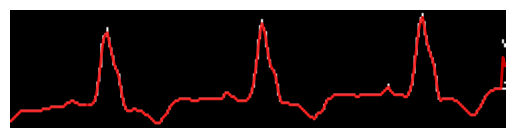

In [12]:
import matplotlib.pyplot as plt

fname = "mask_18636_00_I.jpg"
img_path = os.path.join(output_segmentation_normal,"masks", fname)

res = evaluate_single_mask(img_path, meta, wfdb_root)

if res is not None:
    # Read the mask image
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    plt.imshow(skel_mask, cmap='gray', origin='upper')
    # plt.plot(predicted_x_clean, gt_y, color='green', linewidth=1, label='GT', alpha=0.8)
    plt.plot(predicted_x_clean, predicted_y_clean, color='red', linewidth=2, label='Pred', alpha=0.8)
    # plt.legend(loc='upper right')
    plt.axis('off')
    plt.show()


### noise

In [68]:
import csv
output_degraded = "" # Fill with your own path
csv_path = "" # Fill with your own path
if not os.path.exists(csv_path):
    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writeheader()

In [69]:
import matplotlib.pyplot as plt

# fname = "mask_18636_00_I.jpg"
# img_path = os.path.join(output_segmentation_normal,"masks", fname)

mask_dir = os.path.join(output_degraded, "masks")

results = []

for fname in tqdm(sorted(os.listdir(mask_dir))):
    # Read the mask image
    img_path = os.path.join(mask_dir, fname)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    with open(csv_path, mode="a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writerow({
            "file": fname,
            "RMSE_mV": rmse_mv,
            "PCC": pcc,
            "SNR_dB": snr_db
        })


 67%|██████▋   | 16/24 [00:00<00:00, 77.09it/s]

SNR: 22.81 dB, RMSE: 0.0515 mV, PCC: 0.8463
SNR: 23.98 dB, RMSE: 0.0601 mV, PCC: 0.9412
SNR: 12.86 dB, RMSE: 0.0427 mV, PCC: 0.9565
SNR: 14.74 dB, RMSE: 0.0454 mV, PCC: 0.9611
SNR: 19.30 dB, RMSE: 0.0609 mV, PCC: 0.9786
SNR: 18.94 dB, RMSE: 0.0588 mV, PCC: 0.9386
SNR: 22.18 dB, RMSE: 0.0759 mV, PCC: 0.8646
SNR: 20.75 dB, RMSE: 0.1121 mV, PCC: 0.7784
SNR: 26.49 dB, RMSE: 0.0465 mV, PCC: 0.9730
SNR: 18.18 dB, RMSE: 0.0298 mV, PCC: 0.9402
SNR: 26.92 dB, RMSE: 0.0258 mV, PCC: 0.9662
SNR: 21.14 dB, RMSE: 0.0353 mV, PCC: 0.8498
SNR: 15.80 dB, RMSE: 0.0594 mV, PCC: 0.9454
SNR: 18.74 dB, RMSE: 0.0490 mV, PCC: 0.9651
SNR: 18.14 dB, RMSE: 0.0806 mV, PCC: 0.8709
SNR: 21.90 dB, RMSE: 0.0675 mV, PCC: 0.9161
SNR: 22.57 dB, RMSE: 0.0503 mV, PCC: 0.9368
SNR: 23.05 dB, RMSE: 0.0692 mV, PCC: 0.9146
SNR: 15.43 dB, RMSE: 0.0604 mV, PCC: 0.9015
SNR: 14.62 dB, RMSE: 0.0487 mV, PCC: 0.9708


100%|██████████| 24/24 [00:00<00:00, 79.93it/s]

SNR: 11.93 dB, RMSE: 0.1635 mV, PCC: 0.8528
SNR: 13.15 dB, RMSE: 0.2649 mV, PCC: 0.6287
SNR: 13.61 dB, RMSE: 0.3096 mV, PCC: 0.5207
SNR: 17.72 dB, RMSE: 0.1576 mV, PCC: 0.6446


In [70]:
df = pd.read_csv(csv_path)
print(df.describe())

         RMSE_mV        PCC     SNR_dB
count  24.000000  24.000000  24.000000
mean    0.084398   0.877597  18.955415
std     0.071501   0.120858   4.314101
min     0.025770   0.520666  11.927283
25%     0.048118   0.852034  15.256268
50%     0.059786   0.926448  18.836930
75%     0.077045   0.957669  22.280330
max     0.309608   0.978587  26.917762


### blur3

In [71]:
import csv
output_degraded = "" # Fill with your own path
csv_path = "" # Fill with your own path
if not os.path.exists(csv_path):
    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writeheader()

In [72]:
import matplotlib.pyplot as plt

# fname = "mask_18636_00_I.jpg"
# img_path = os.path.join(output_segmentation_normal,"masks", fname)

mask_dir = os.path.join(output_degraded, "masks")

results = []

for fname in tqdm(sorted(os.listdir(mask_dir))):
    # Read the mask image
    img_path = os.path.join(mask_dir, fname)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    with open(csv_path, mode="a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writerow({
            "file": fname,
            "RMSE_mV": rmse_mv,
            "PCC": pcc,
            "SNR_dB": snr_db
        })


 29%|██▉       | 7/24 [00:00<00:00, 63.04it/s]

SNR: 23.92 dB, RMSE: 0.0455 mV, PCC: 0.8844
SNR: 24.25 dB, RMSE: 0.0581 mV, PCC: 0.9435
SNR: 12.28 dB, RMSE: 0.0460 mV, PCC: 0.9466
SNR: 14.65 dB, RMSE: 0.0468 mV, PCC: 0.9602
SNR: 18.87 dB, RMSE: 0.0652 mV, PCC: 0.9795
SNR: 19.46 dB, RMSE: 0.0555 mV, PCC: 0.9509
SNR: 20.00 dB, RMSE: 0.0963 mV, PCC: 0.7937
SNR: 20.71 dB, RMSE: 0.1128 mV, PCC: 0.7760
SNR: 26.59 dB, RMSE: 0.0461 mV, PCC: 0.9778
SNR: 17.83 dB, RMSE: 0.0311 mV, PCC: 0.9364
SNR: 26.61 dB, RMSE: 0.0268 mV, PCC: 0.9659


 83%|████████▎ | 20/24 [00:00<00:00, 44.92it/s]

SNR: 21.50 dB, RMSE: 0.0338 mV, PCC: 0.8688
SNR: 15.32 dB, RMSE: 0.0626 mV, PCC: 0.9399
SNR: 19.98 dB, RMSE: 0.0426 mV, PCC: 0.9753
SNR: 18.04 dB, RMSE: 0.0823 mV, PCC: 0.8663
SNR: 25.72 dB, RMSE: 0.0437 mV, PCC: 0.9771
SNR: 22.46 dB, RMSE: 0.0510 mV, PCC: 0.9365
SNR: 22.71 dB, RMSE: 0.0721 mV, PCC: 0.9087
SNR: 15.50 dB, RMSE: 0.0597 mV, PCC: 0.9047
SNR: 15.02 dB, RMSE: 0.0472 mV, PCC: 0.9753


100%|██████████| 24/24 [00:00<00:00, 48.45it/s]

SNR: 11.40 dB, RMSE: 0.1770 mV, PCC: 0.8485
SNR: 10.94 dB, RMSE: 0.3406 mV, PCC: 0.6006
SNR: 11.36 dB, RMSE: 0.4162 mV, PCC: 0.5677
SNR: 17.59 dB, RMSE: 0.1602 mV, PCC: 0.6356


In [73]:
df = pd.read_csv(csv_path)
print(df.describe())

         RMSE_mV        PCC     SNR_dB
count  24.000000  24.000000  24.000000
mean    0.092469   0.879998  18.863239
std     0.096245   0.121700   4.846388
min     0.026804   0.567711  10.940429
25%     0.045858   0.861846  15.246704
50%     0.056777   0.936443  19.165525
75%     0.085795   0.961584  22.523683
max     0.416213   0.979500  26.613621


### blur5

In [74]:
import csv
output_degraded = "" # Fill with your own path
csv_path = "" # Fill with your own path
if not os.path.exists(csv_path):
    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writeheader()

In [75]:
import matplotlib.pyplot as plt

# fname = "mask_18636_00_I.jpg"
# img_path = os.path.join(output_segmentation_normal,"masks", fname)

mask_dir = os.path.join(output_degraded, "masks")

results = []

for fname in tqdm(sorted(os.listdir(mask_dir))):
    # Read the mask image
    img_path = os.path.join(mask_dir, fname)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    with open(csv_path, mode="a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writerow({
            "file": fname,
            "RMSE_mV": rmse_mv,
            "PCC": pcc,
            "SNR_dB": snr_db
        })


 25%|██▌       | 6/24 [00:00<00:00, 55.20it/s]

SNR: 23.65 dB, RMSE: 0.0471 mV, PCC: 0.8753
SNR: 24.10 dB, RMSE: 0.0592 mV, PCC: 0.9435
SNR: 11.94 dB, RMSE: 0.0494 mV, PCC: 0.9401
SNR: 14.92 dB, RMSE: 0.0469 mV, PCC: 0.9649
SNR: 17.87 dB, RMSE: 0.0746 mV, PCC: 0.9694
SNR: 19.81 dB, RMSE: 0.0540 mV, PCC: 0.9575
SNR: 19.37 dB, RMSE: 0.1031 mV, PCC: 0.7748
SNR: 20.65 dB, RMSE: 0.1127 mV, PCC: 0.7851
SNR: 26.60 dB, RMSE: 0.0460 mV, PCC: 0.9791
SNR: 17.82 dB, RMSE: 0.0311 mV, PCC: 0.9397
SNR: 26.41 dB, RMSE: 0.0274 mV, PCC: 0.9649


 71%|███████   | 17/24 [00:00<00:00, 45.34it/s]

SNR: 22.09 dB, RMSE: 0.0317 mV, PCC: 0.8904
SNR: 15.04 dB, RMSE: 0.0650 mV, PCC: 0.9398
SNR: 18.50 dB, RMSE: 0.0501 mV, PCC: 0.9692
SNR: 17.98 dB, RMSE: 0.0835 mV, PCC: 0.8651
SNR: 25.43 dB, RMSE: 0.0452 mV, PCC: 0.9763
SNR: 22.05 dB, RMSE: 0.0533 mV, PCC: 0.9318
SNR: 22.66 dB, RMSE: 0.0727 mV, PCC: 0.9070
SNR: 15.74 dB, RMSE: 0.0587 mV, PCC: 0.9131
SNR: 15.18 dB, RMSE: 0.0467 mV, PCC: 0.9789


100%|██████████| 24/24 [00:00<00:00, 44.57it/s]

SNR: 10.57 dB, RMSE: 0.1981 mV, PCC: 0.8519
SNR: 9.46 dB, RMSE: 0.3996 mV, PCC: 0.5645
SNR: 10.13 dB, RMSE: 0.4880 mV, PCC: 0.5483
SNR: 17.16 dB, RMSE: 0.1685 mV, PCC: 0.6264


In [76]:
df = pd.read_csv(csv_path)
print(df.describe())

         RMSE_mV        PCC     SNR_dB
count  24.000000  24.000000  24.000000
mean    0.100532   0.877377  18.547199
std     0.114099   0.128450   5.055808
min     0.027417   0.548298   9.462380
25%     0.046871   0.861780  15.141224
50%     0.056391   0.935767  18.238445
75%     0.088392   0.964872  22.233432
max     0.487970   0.979134  26.596321


### stains3

In [77]:
import csv
output_degraded = "" # Fill with your own path
csv_path = "" # Fill with your own path
if not os.path.exists(csv_path):
    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writeheader()

In [78]:
import matplotlib.pyplot as plt

# fname = "mask_18636_00_I.jpg"
# img_path = os.path.join(output_segmentation_normal,"masks", fname)

mask_dir = os.path.join(output_degraded, "masks")

results = []

for fname in tqdm(sorted(os.listdir(mask_dir))):
    # Read the mask image
    img_path = os.path.join(mask_dir, fname)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    with open(csv_path, mode="a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writerow({
            "file": fname,
            "RMSE_mV": rmse_mv,
            "PCC": pcc,
            "SNR_dB": snr_db
        })


 42%|████▏     | 10/24 [00:00<00:00, 44.94it/s]

SNR: 23.24 dB, RMSE: 0.0491 mV, PCC: 0.8614
SNR: 23.54 dB, RMSE: 0.0632 mV, PCC: 0.9307
SNR: 8.23 dB, RMSE: 0.0761 mV, PCC: 0.8224
SNR: 14.50 dB, RMSE: 0.0468 mV, PCC: 0.9573
SNR: 18.90 dB, RMSE: 0.0638 mV, PCC: 0.9765
SNR: 19.03 dB, RMSE: 0.0577 mV, PCC: 0.9412
SNR: 21.08 dB, RMSE: 0.0859 mV, PCC: 0.8209
SNR: 20.42 dB, RMSE: 0.1161 mV, PCC: 0.7608
SNR: 23.57 dB, RMSE: 0.0649 mV, PCC: 0.9272
SNR: 17.21 dB, RMSE: 0.0331 mV, PCC: 0.9193


 62%|██████▎   | 15/24 [00:00<00:00, 43.11it/s]

SNR: 27.02 dB, RMSE: 0.0255 mV, PCC: 0.9669
SNR: 19.92 dB, RMSE: 0.0403 mV, PCC: 0.7967
SNR: 15.61 dB, RMSE: 0.0604 mV, PCC: 0.9453
SNR: 18.38 dB, RMSE: 0.0510 mV, PCC: 0.9631
SNR: 18.14 dB, RMSE: 0.0808 mV, PCC: 0.8655
SNR: 24.26 dB, RMSE: 0.0516 mV, PCC: 0.9603
SNR: 19.23 dB, RMSE: 0.0729 mV, PCC: 0.8340
SNR: 20.81 dB, RMSE: 0.0885 mV, PCC: 0.8523
SNR: 15.32 dB, RMSE: 0.0614 mV, PCC: 0.8983


100%|██████████| 24/24 [00:00<00:00, 45.16it/s]

SNR: 13.07 dB, RMSE: 0.0587 mV, PCC: 0.9537
SNR: 11.65 dB, RMSE: 0.1713 mV, PCC: 0.8367
SNR: 12.78 dB, RMSE: 0.2741 mV, PCC: 0.6331
SNR: 14.61 dB, RMSE: 0.2792 mV, PCC: 0.5887
SNR: 17.75 dB, RMSE: 0.1568 mV, PCC: 0.6447


In [79]:
df = pd.read_csv(csv_path)
print(df.describe())

         RMSE_mV        PCC     SNR_dB
count  24.000000  24.000000  24.000000
mean    0.088714   0.860706  18.261310
std     0.067293   0.110698   4.487445
min     0.025485   0.588689   8.232099
25%     0.051446   0.822052  15.143724
50%     0.063530   0.881901  18.640425
75%     0.086529   0.947390  20.880072
max     0.279215   0.976508  27.023336


### stains5

In [80]:
import csv
output_degraded = "" # Fill with your own path
csv_path = "" # Fill with your own path
if not os.path.exists(csv_path):
    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writeheader()

In [81]:
import matplotlib.pyplot as plt

# fname = "mask_18636_00_I.jpg"
# img_path = os.path.join(output_segmentation_normal,"masks", fname)

mask_dir = os.path.join(output_degraded, "masks")

results = []

for fname in tqdm(sorted(os.listdir(mask_dir))):
    # Read the mask image
    img_path = os.path.join(mask_dir, fname)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    with open(csv_path, mode="a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writerow({
            "file": fname,
            "RMSE_mV": rmse_mv,
            "PCC": pcc,
            "SNR_dB": snr_db
        })


 29%|██▉       | 7/24 [00:00<00:00, 60.70it/s]

SNR: 22.96 dB, RMSE: 0.0508 mV, PCC: 0.8580
SNR: 23.50 dB, RMSE: 0.0639 mV, PCC: 0.9319
SNR: 12.80 dB, RMSE: 0.0445 mV, PCC: 0.9557
SNR: 11.82 dB, RMSE: 0.0650 mV, PCC: 0.9143
SNR: 19.71 dB, RMSE: 0.0579 mV, PCC: 0.9820
SNR: 18.54 dB, RMSE: 0.0619 mV, PCC: 0.9310
SNR: 21.88 dB, RMSE: 0.0784 mV, PCC: 0.8534
SNR: 20.40 dB, RMSE: 0.1166 mV, PCC: 0.7580
SNR: 24.60 dB, RMSE: 0.0576 mV, PCC: 0.9479
SNR: 18.05 dB, RMSE: 0.0302 mV, PCC: 0.9387
SNR: 27.23 dB, RMSE: 0.0249 mV, PCC: 0.9694


 79%|███████▉  | 19/24 [00:00<00:00, 45.81it/s]

SNR: 20.78 dB, RMSE: 0.0367 mV, PCC: 0.8355
SNR: 15.60 dB, RMSE: 0.0606 mV, PCC: 0.9436
SNR: 18.58 dB, RMSE: 0.0498 mV, PCC: 0.9657
SNR: 18.08 dB, RMSE: 0.0817 mV, PCC: 0.8654
SNR: 24.19 dB, RMSE: 0.0520 mV, PCC: 0.9604
SNR: 22.63 dB, RMSE: 0.0500 mV, PCC: 0.9372
SNR: 22.00 dB, RMSE: 0.0776 mV, PCC: 0.8879
SNR: 15.16 dB, RMSE: 0.0623 mV, PCC: 0.8955
SNR: 14.45 dB, RMSE: 0.0495 mV, PCC: 0.9695


100%|██████████| 24/24 [00:00<00:00, 44.31it/s]

SNR: 11.58 dB, RMSE: 0.1699 mV, PCC: 0.8426
SNR: 13.10 dB, RMSE: 0.2655 mV, PCC: 0.6618
SNR: 14.51 dB, RMSE: 0.2818 mV, PCC: 0.5746
SNR: 17.84 dB, RMSE: 0.1553 mV, PCC: 0.6502


In [82]:
df = pd.read_csv(csv_path)
print(df.describe())

         RMSE_mV        PCC     SNR_dB
count  24.000000  24.000000  24.000000
mean    0.085193   0.876259  18.749900
std     0.067600   0.110554   4.409445
min     0.024920   0.574567  11.575084
25%     0.049975   0.850691  15.000402
50%     0.061271   0.922659  18.564001
75%     0.079251   0.949853  22.157200
max     0.281760   0.981997  27.229933


### stains7

In [106]:
import csv
output_degraded = "" # Fill with your own path
csv_path = "" # Fill with your own path
if not os.path.exists(csv_path):
    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writeheader()

In [107]:
import matplotlib.pyplot as plt

# fname = "mask_18636_00_I.jpg"
# img_path = os.path.join(output_segmentation_normal,"masks", fname)

mask_dir = os.path.join(output_degraded, "masks")

results = []

for fname in tqdm(sorted(os.listdir(mask_dir))):
    # Read the mask image
    img_path = os.path.join(mask_dir, fname)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    with open(csv_path, mode="a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writerow({
            "file": fname,
            "RMSE_mV": rmse_mv,
            "PCC": pcc,
            "SNR_dB": snr_db
        })


 29%|██▉       | 7/24 [00:00<00:00, 61.02it/s]

SNR: 22.05 dB, RMSE: 0.0562 mV, PCC: 0.8221
SNR: 23.70 dB, RMSE: 0.0623 mV, PCC: 0.9370
SNR: 11.94 dB, RMSE: 0.0501 mV, PCC: 0.9357
SNR: 12.63 dB, RMSE: 0.0588 mV, PCC: 0.9298
SNR: 18.09 dB, RMSE: 0.0696 mV, PCC: 0.9727
SNR: 18.39 dB, RMSE: 0.0618 mV, PCC: 0.9321
SNR: 22.09 dB, RMSE: 0.0766 mV, PCC: 0.8618
SNR: 19.03 dB, RMSE: 0.1355 mV, PCC: 0.6805
SNR: 25.93 dB, RMSE: 0.0497 mV, PCC: 0.9684
SNR: 16.43 dB, RMSE: 0.0359 mV, PCC: 0.9036
SNR: 24.82 dB, RMSE: 0.0330 mV, PCC: 0.9380


 83%|████████▎ | 20/24 [00:00<00:00, 48.98it/s]

SNR: 21.45 dB, RMSE: 0.0340 mV, PCC: 0.8611
SNR: 15.62 dB, RMSE: 0.0604 mV, PCC: 0.9441
SNR: 19.41 dB, RMSE: 0.0468 mV, PCC: 0.9697
SNR: 17.61 dB, RMSE: 0.0850 mV, PCC: 0.8641
SNR: 21.66 dB, RMSE: 0.0691 mV, PCC: 0.9101
SNR: 20.06 dB, RMSE: 0.0674 mV, PCC: 0.8553
SNR: 21.39 dB, RMSE: 0.0836 mV, PCC: 0.8748
SNR: 13.71 dB, RMSE: 0.0752 mV, PCC: 0.8556
SNR: 14.48 dB, RMSE: 0.0511 mV, PCC: 0.9692
SNR: 11.53 dB, RMSE: 0.1742 mV, PCC: 0.8327


100%|██████████| 24/24 [00:00<00:00, 50.06it/s]

SNR: 13.07 dB, RMSE: 0.2664 mV, PCC: 0.6650
SNR: 13.81 dB, RMSE: 0.3033 mV, PCC: 0.5568
SNR: 17.68 dB, RMSE: 0.1576 mV, PCC: 0.6416


In [108]:
df = pd.read_csv(csv_path)
print(df.describe())

         RMSE_mV        PCC     SNR_dB
count  24.000000  24.000000  24.000000
mean    0.090153   0.861731  18.190380
std     0.069978   0.114201   4.205830
min     0.033027   0.556770  11.534778
25%     0.050862   0.849672  14.311683
50%     0.064816   0.889228  18.239181
75%     0.083958   0.937210  21.503491
max     0.303336   0.972717  25.927524


### stains10

In [83]:
import csv
output_degraded = "" # Fill with your own path
csv_path = "" # Fill with your own path
if not os.path.exists(csv_path):
    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writeheader()

In [84]:
import matplotlib.pyplot as plt

# fname = "mask_18636_00_I.jpg"
# img_path = os.path.join(output_segmentation_normal,"masks", fname)

mask_dir = os.path.join(output_degraded, "masks")

results = []

for fname in tqdm(sorted(os.listdir(mask_dir))):
    # Read the mask image
    img_path = os.path.join(mask_dir, fname)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    with open(csv_path, mode="a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writerow({
            "file": fname,
            "RMSE_mV": rmse_mv,
            "PCC": pcc,
            "SNR_dB": snr_db
        })


 25%|██▌       | 6/24 [00:00<00:00, 58.92it/s]

SNR: 22.77 dB, RMSE: 0.0518 mV, PCC: 0.8613
SNR: 23.74 dB, RMSE: 0.0617 mV, PCC: 0.9417
SNR: 9.98 dB, RMSE: 0.0619 mV, PCC: 0.8889
SNR: 11.65 dB, RMSE: 0.0676 mV, PCC: 0.9080
SNR: 19.64 dB, RMSE: 0.0588 mV, PCC: 0.9816
SNR: 15.80 dB, RMSE: 0.0851 mV, PCC: 0.8733
SNR: 19.57 dB, RMSE: 0.1008 mV, PCC: 0.7546
SNR: 20.25 dB, RMSE: 0.1180 mV, PCC: 0.7677
SNR: 15.03 dB, RMSE: 0.1661 mV, PCC: 0.5748
SNR: 17.20 dB, RMSE: 0.0317 mV, PCC: 0.9350


 71%|███████   | 17/24 [00:00<00:00, 42.78it/s]

SNR: 26.84 dB, RMSE: 0.0261 mV, PCC: 0.9658
SNR: 21.00 dB, RMSE: 0.0361 mV, PCC: 0.8312
SNR: 15.36 dB, RMSE: 0.0624 mV, PCC: 0.9417
SNR: 14.15 dB, RMSE: 0.0900 mV, PCC: 0.8723
SNR: 14.75 dB, RMSE: 0.1204 mV, PCC: 0.7041
SNR: 22.75 dB, RMSE: 0.0616 mV, PCC: 0.9274
SNR: 21.75 dB, RMSE: 0.0551 mV, PCC: 0.9156
SNR: 20.92 dB, RMSE: 0.0881 mV, PCC: 0.8560
SNR: 12.48 dB, RMSE: 0.0913 mV, PCC: 0.7931


100%|██████████| 24/24 [00:00<00:00, 46.21it/s]

SNR: 13.78 dB, RMSE: 0.0535 mV, PCC: 0.9630
SNR: 11.20 dB, RMSE: 0.1798 mV, PCC: 0.8324
SNR: 12.81 dB, RMSE: 0.2712 mV, PCC: 0.6405
SNR: 14.06 dB, RMSE: 0.2943 mV, PCC: 0.5742
SNR: 16.72 dB, RMSE: 0.1773 mV, PCC: 0.5883


In [85]:
df = pd.read_csv(csv_path)
print(df.describe())

         RMSE_mV        PCC     SNR_dB
count  24.000000  24.000000  24.000000
mean    0.100454   0.828851  17.258921
std     0.070511   0.128278   4.543941
min     0.026145   0.574184   9.983464
25%     0.057854   0.764416  13.989447
50%     0.076341   0.866775  16.257900
75%     0.118615   0.929325  20.939949
max     0.294346   0.981623  26.842036


### low brightness

In [86]:
import csv
output_degraded = "" # Fill with your own path
csv_path = "" # Fill with your own path
if not os.path.exists(csv_path):
    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writeheader()

In [87]:
import matplotlib.pyplot as plt

# fname = "mask_18636_00_I.jpg"
# img_path = os.path.join(output_segmentation_normal,"masks", fname)

mask_dir = os.path.join(output_degraded, "masks")

results = []

for fname in tqdm(sorted(os.listdir(mask_dir))):
    # Read the mask image
    img_path = os.path.join(mask_dir, fname)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    with open(csv_path, mode="a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writerow({
            "file": fname,
            "RMSE_mV": rmse_mv,
            "PCC": pcc,
            "SNR_dB": snr_db
        })


 25%|██▌       | 6/24 [00:00<00:00, 58.84it/s]

SNR: 23.36 dB, RMSE: 0.0485 mV, PCC: 0.8666
SNR: 23.96 dB, RMSE: 0.0603 mV, PCC: 0.9377
SNR: 13.11 dB, RMSE: 0.0416 mV, PCC: 0.9611
SNR: 14.33 dB, RMSE: 0.0481 mV, PCC: 0.9575
SNR: 19.92 dB, RMSE: 0.0568 mV, PCC: 0.9827
SNR: 19.76 dB, RMSE: 0.0531 mV, PCC: 0.9510
SNR: 22.45 dB, RMSE: 0.0736 mV, PCC: 0.8755
SNR: 20.63 dB, RMSE: 0.1139 mV, PCC: 0.7702
SNR: 26.36 dB, RMSE: 0.0473 mV, PCC: 0.9728
SNR: 18.43 dB, RMSE: 0.0290 mV, PCC: 0.9434
SNR: 27.04 dB, RMSE: 0.0255 mV, PCC: 0.9668


 71%|███████   | 17/24 [00:00<00:00, 46.89it/s]

SNR: 21.34 dB, RMSE: 0.0345 mV, PCC: 0.8592
SNR: 15.63 dB, RMSE: 0.0604 mV, PCC: 0.9436
SNR: 19.27 dB, RMSE: 0.0459 mV, PCC: 0.9739
SNR: 18.24 dB, RMSE: 0.0798 mV, PCC: 0.8788
SNR: 24.05 dB, RMSE: 0.0529 mV, PCC: 0.9591
SNR: 22.45 dB, RMSE: 0.0512 mV, PCC: 0.9359
SNR: 22.64 dB, RMSE: 0.0726 mV, PCC: 0.9062
SNR: 15.56 dB, RMSE: 0.0595 mV, PCC: 0.9050
SNR: 14.15 dB, RMSE: 0.0519 mV, PCC: 0.9678
SNR: 11.71 dB, RMSE: 0.1672 mV, PCC: 0.8516


100%|██████████| 24/24 [00:00<00:00, 48.16it/s]

SNR: 11.98 dB, RMSE: 0.2999 mV, PCC: 0.6279
SNR: 13.93 dB, RMSE: 0.3021 mV, PCC: 0.5812
SNR: 17.64 dB, RMSE: 0.1590 mV, PCC: 0.6314


In [88]:
df = pd.read_csv(csv_path)
print(df.describe())

         RMSE_mV        PCC     SNR_dB
count  24.000000  24.000000  24.000000
mean    0.084767   0.883618  19.080996
std     0.075285   0.116225   4.513580
min     0.025491   0.581189  11.707877
25%     0.047892   0.864749  15.250144
50%     0.054916   0.936786  19.515100
75%     0.075115   0.959629  22.496918
max     0.302066   0.982694  27.037968


### high brightness

In [89]:
import csv
output_degraded = "" # Fill with your own path
csv_path = "" # Fill with your own path
if not os.path.exists(csv_path):
    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writeheader()

In [90]:
import matplotlib.pyplot as plt

# fname = "mask_18636_00_I.jpg"
# img_path = os.path.join(output_segmentation_normal,"masks", fname)

mask_dir = os.path.join(output_degraded, "masks")

results = []

for fname in tqdm(sorted(os.listdir(mask_dir))):
    # Read the mask image
    img_path = os.path.join(mask_dir, fname)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    with open(csv_path, mode="a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writerow({
            "file": fname,
            "RMSE_mV": rmse_mv,
            "PCC": pcc,
            "SNR_dB": snr_db
        })


 29%|██▉       | 7/24 [00:00<00:00, 62.44it/s]

SNR: 22.61 dB, RMSE: 0.0526 mV, PCC: 0.8400
SNR: 22.38 dB, RMSE: 0.0722 mV, PCC: 0.9045
SNR: 12.74 dB, RMSE: 0.0435 mV, PCC: 0.9537
SNR: 14.65 dB, RMSE: 0.0453 mV, PCC: 0.9624
SNR: 19.65 dB, RMSE: 0.0584 mV, PCC: 0.9814
SNR: 18.50 dB, RMSE: 0.0619 mV, PCC: 0.9330
SNR: 21.96 dB, RMSE: 0.0776 mV, PCC: 0.8566
SNR: 20.34 dB, RMSE: 0.1175 mV, PCC: 0.7532
SNR: 26.09 dB, RMSE: 0.0487 mV, PCC: 0.9713
SNR: 18.05 dB, RMSE: 0.0302 mV, PCC: 0.9368
SNR: 26.90 dB, RMSE: 0.0258 mV, PCC: 0.9668
SNR: 21.27 dB, RMSE: 0.0346 mV, PCC: 0.8548


 83%|████████▎ | 20/24 [00:00<00:00, 44.37it/s]

SNR: 15.85 dB, RMSE: 0.0587 mV, PCC: 0.9476
SNR: 18.53 dB, RMSE: 0.0502 mV, PCC: 0.9628
SNR: 18.01 dB, RMSE: 0.0820 mV, PCC: 0.8660
SNR: 23.75 dB, RMSE: 0.0547 mV, PCC: 0.9534
SNR: 22.62 dB, RMSE: 0.0500 mV, PCC: 0.9386
SNR: 22.46 dB, RMSE: 0.0738 mV, PCC: 0.8997
SNR: 15.57 dB, RMSE: 0.0591 mV, PCC: 0.9062
SNR: 13.72 dB, RMSE: 0.0539 mV, PCC: 0.9628
SNR: 11.09 dB, RMSE: 0.1826 mV, PCC: 0.8190


100%|██████████| 24/24 [00:00<00:00, 45.93it/s]

SNR: 13.61 dB, RMSE: 0.2520 mV, PCC: 0.6657
SNR: 13.90 dB, RMSE: 0.3002 mV, PCC: 0.5381
SNR: 17.73 dB, RMSE: 0.1571 mV, PCC: 0.6448


In [91]:
df = pd.read_csv(csv_path)
print(df.describe())

         RMSE_mV        PCC     SNR_dB
count  24.000000  24.000000  24.000000
mean    0.085107   0.875806  18.832567
std     0.069765   0.116780   4.321542
min     0.025791   0.538144  11.086330
25%     0.049670   0.851105  15.341821
50%     0.058539   0.919608  18.514056
75%     0.078723   0.955891  22.400494
max     0.300200   0.981396  26.904803


### normal

In [95]:
import csv
output_degraded = "" # Fill with your own path
csv_path = "" # Fill with your own path
if not os.path.exists(csv_path):
    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writeheader()

In [96]:
import matplotlib.pyplot as plt

# fname = "mask_18636_00_I.jpg"
# img_path = os.path.join(output_segmentation_normal,"masks", fname)

mask_dir = os.path.join(output_degraded, "masks")

results = []

for fname in tqdm(sorted(os.listdir(mask_dir))):
    # Read the mask image
    img_path = os.path.join(mask_dir, fname)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    with open(csv_path, mode="a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["file", "RMSE_mV", "PCC", "SNR_dB"]
        )
        writer.writerow({
            "file": fname,
            "RMSE_mV": rmse_mv,
            "PCC": pcc,
            "SNR_dB": snr_db
        })


 25%|██▌       | 6/24 [00:00<00:00, 59.07it/s]

SNR: 23.38 dB, RMSE: 0.0483 mV, PCC: 0.8663
SNR: 23.94 dB, RMSE: 0.0606 mV, PCC: 0.9396
SNR: 12.72 dB, RMSE: 0.0436 mV, PCC: 0.9533
SNR: 14.91 dB, RMSE: 0.0445 mV, PCC: 0.9626
SNR: 19.81 dB, RMSE: 0.0571 mV, PCC: 0.9818
SNR: 18.90 dB, RMSE: 0.0587 mV, PCC: 0.9389
SNR: 22.35 dB, RMSE: 0.0745 mV, PCC: 0.8706
SNR: 20.79 dB, RMSE: 0.1116 mV, PCC: 0.7805
SNR: 26.30 dB, RMSE: 0.0476 mV, PCC: 0.9727
SNR: 18.33 dB, RMSE: 0.0292 mV, PCC: 0.9432


 71%|███████   | 17/24 [00:00<00:00, 42.21it/s]

SNR: 27.20 dB, RMSE: 0.0250 mV, PCC: 0.9689
SNR: 21.47 dB, RMSE: 0.0339 mV, PCC: 0.8621
SNR: 15.69 dB, RMSE: 0.0602 mV, PCC: 0.9440
SNR: 19.12 dB, RMSE: 0.0467 mV, PCC: 0.9702
SNR: 18.19 dB, RMSE: 0.0807 mV, PCC: 0.8672
SNR: 25.30 dB, RMSE: 0.0459 mV, PCC: 0.9728
SNR: 22.51 dB, RMSE: 0.0507 mV, PCC: 0.9355
SNR: 22.92 dB, RMSE: 0.0702 mV, PCC: 0.9114
SNR: 15.56 dB, RMSE: 0.0595 mV, PCC: 0.9047


100%|██████████| 24/24 [00:00<00:00, 45.28it/s]

SNR: 14.44 dB, RMSE: 0.0494 mV, PCC: 0.9699
SNR: 11.72 dB, RMSE: 0.1674 mV, PCC: 0.8470
SNR: 13.18 dB, RMSE: 0.2644 mV, PCC: 0.6571
SNR: 14.35 dB, RMSE: 0.2868 mV, PCC: 0.5673
SNR: 17.84 dB, RMSE: 0.1553 mV, PCC: 0.6508


In [97]:
df = pd.read_csv(csv_path)
print(df.describe())

         RMSE_mV        PCC     SNR_dB
count  24.000000  24.000000  24.000000
mean    0.082157   0.884928  19.205399
std     0.069067   0.113226   4.483791
min     0.024986   0.567254  11.721137
25%     0.046520   0.865242  15.398287
50%     0.057886   0.937191  19.008445
75%     0.076042   0.964146  22.615175
max     0.286822   0.981845  27.198789


### points

SNR: 23.96 dB, RMSE: 0.0603 mV, PCC: 0.9377


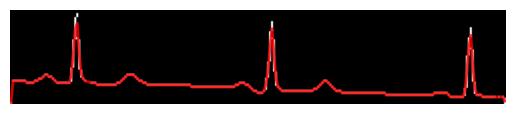

In [17]:
import matplotlib.pyplot as plt
output_degraded = "" # Fill with your own path
fname = "mask_18568_01_II.jpg"
img_path = os.path.join(output_degraded,"masks", fname)

res = evaluate_single_mask(img_path, meta, wfdb_root)

if res is not None:
    # Read the mask image
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W = img_mask.shape[:2]

    # Extract predicted raw points
    predicted_raw, skel_mask = extract_ecg(img_mask)
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)
    
    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]

    # Average y for same x
    x_unique = np.unique(predicted_x_clean)
    y_center = [np.mean(predicted_y_clean[predicted_x_clean == x]) for x in x_unique]
    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    # Compute GT in pixels
    parts = fname.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        lead_map = {'I':0,'II':1,'III':2,'aVR':3,'aVL':4,'aVF':5,'V1':6,'V2':7,'V3':8,'V4':9,'V5':10,'V6':11}
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0,1,len(signal))
    x_new = np.linspace(0,1,W)
    signal = np.interp(x_new,x_old,signal)
    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    print(f"SNR: {snr_db:.2f} dB, RMSE: {rmse_mv:.4f} mV, PCC: {pcc:.4f}")
    plt.imshow(skel_mask, cmap='gray', origin='upper')
    # plt.plot(predicted_x_clean, gt_y, color='green', linewidth=1, label='GT', alpha=0.8)
    plt.plot(predicted_x_clean, predicted_y_clean, color='red', linewidth=2, label='Pred', alpha=0.8)
    # plt.legend(loc='upper right')
    plt.axis('off')
    plt.show()


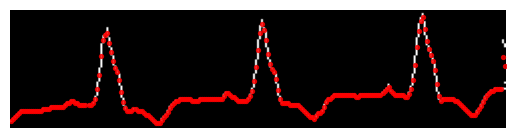

In [14]:
plt.imshow(skel_mask, cmap='gray', origin='upper')

# plt.scatter(
#     predicted_x_clean, gt_y,
#     s=5, c='green', label='GT', alpha=0.8
# )

plt.scatter(
    predicted_x_clean, predicted_y_clean,
    s=8, c='red', label='Pred', alpha=0.8
)

# plt.legend(loc='upper right')
plt.axis('off')
plt.show()
